# 08. PDE를 이용한 옵션 가치평가

가격격자와 시간격자를 만든 뒤, 만기 payoff에서 현재시점 가격으로 거슬러 계산합니다.
강의록의 모든 코드와 비교용 출력을 원문 순서대로 수록했습니다.

**사용 방법:** 같은 폴더의 파일 구성을 유지한 채 Python 커널에서 **Restart Kernel → Run All**을 선택하세요.
앞 장을 실행하지 않아도 이 노트북만으로 실습할 수 있습니다. 아래 결과와 그림은 실제 실행 결과입니다.

**학습 순서**

1. 가격격자와 3-point stencil
2. 만기조건, 경계조건, implicit Euler 가격함수
3. 가격곡선·put–call parity·격자오차 확인
4. 미국형 옵션의 교육용 projected scheme
5. CEV local volatility와 Heston 9-point stencil

남은 만기 $\tau=T-t$를 쓰면 초기값은 payoff이고, $\partial_\tau u=\mathcal L u$를 풀게 됩니다.
위험중립측도는 $\mathbb{Q}$이며, 이 장의 모형 드리프트는 $r-q$입니다.

In [1]:
%matplotlib inline

### 이번 장에서 사용할 라이브러리 불러오기

NumPy 배열에 격자값을 저장하고 SciPy의 희소행렬 분해로 매 시간단계의 연립방정식을 풉니다.

원문: `section08_pde_option_pricing.tex` · Listing 1 · 132행

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.sparse import diags
from scipy.sparse.linalg import splu

### 가격격자와 시간격자 만들기

공간구간이 400개이면 격자점은 401개입니다. 시간격자도 마지막 시점을 포함하므로 1001개가 됩니다.

원문: `section08_pde_option_pricing.tex` · Listing 2 · 163행

In [3]:
strike = 100.0
maturity = 1.0
s_max = 300.0
n_space = 400
n_time = 1000

stock_grid = np.linspace(0.0, s_max, num=n_space + 1)
tau_grid = np.linspace(0.0, maturity, num=n_time + 1)

d_s = s_max / n_space
d_tau = maturity / n_time

print(stock_grid.shape)
print(tau_grid.shape)
print(d_s, d_tau)

(401,)
(1001,)
0.75 0.001


**강의록 Listing 3**

강의록에 실린 비교용 출력입니다. 위 코드 셀의 출력은 이 노트북을 실제 실행해서 저장한 결과입니다.

```text
(401,)
(1001,)
0.75 0.001
```

### Black–Scholes 공간계수 계산하기

내부격자에서 $\mathcal L_h u_i=a_i u_{i-1}+b_i u_i+c_i u_{i+1}$의 세 계수를 계산합니다.

원문: `section08_pde_option_pricing.tex` · Listing 4 · 239행

In [4]:
rate = 0.05
dividend_yield = 0.0
volatility = 0.20

interior_stock = stock_grid[1:-1]
diffusion = 0.5 * volatility**2 * interior_stock**2
convection = (rate - dividend_yield) * interior_stock

lower = diffusion / d_s**2 - convection / (2.0 * d_s)
center = -2.0 * diffusion / d_s**2 - rate
upper = diffusion / d_s**2 + convection / (2.0 * d_s)

**노트북 실행을 위한 보충: 한 단계 갱신의 입력 배열**

`values`에는 만기 콜 payoff를, `next_values`에는 결과를 저장합니다. 원문 갱신식은 다음 셀에 그대로 둡니다.

In [5]:
values = np.maximum(stock_grid - strike, 0.0)
next_values = values.copy()

### Explicit Euler의 내부격자 한 단계

강의록의 한 줄짜리 갱신식을 그대로 실행합니다. 바로 앞의 보조 셀에서 만기 payoff와 결과를 담을 배열을 준비했습니다. 현재 시간간격은 implicit 예제용이므로 explicit 계산을 여러 번 반복하기 위한 안정성이 보장되지 않습니다.

원문: `section08_pde_option_pricing.tex` · Listing 5 · 268행

In [6]:
next_values[1:-1] = values[1:-1] + d_tau * (lower * values[:-2] + center * values[1:-1] + upper * values[2:])

In [7]:
next_values[0] = 0.0
next_values[-1] = s_max * np.exp(-dividend_yield * d_tau) - strike * np.exp(-rate * d_tau)
print(f"one-step minimum: {next_values.min():.6f}")
print(f"one-step maximum: {next_values.max():.6f}")
print(f"minimum center weight: {(1.0 + d_tau * center).min():.6f}")
print(f"nonnegative-center-weight dt bound: {1.0 / (-center).max():.8f}")

one-step minimum: 0.000000
one-step maximum: 200.005000
minimum center weight: -5.368090
nonnegative-center-weight dt bound: 0.00015703


중앙 가중치가 음수이므로 이 `d_tau`로 explicit Euler를 여러 단계 반복하는 데에는 안정성 문제가 있습니다. 아래 가격함수는 implicit Euler로 구현합니다.

### 격자 전체에서 만기 payoff 만들기

행사가격 아래와 위에서 payoff가 어떻게 달라지는지 확인하세요. 이후 함수들이 이 함수를 호출합니다.

원문: `section08_pde_option_pricing.tex` · Listing 6 · 383행

In [8]:
def option_payoff_grid(stock_grid, strike, option_type):
    stock_grid = np.asarray(stock_grid, dtype=float)
    strike = float(strike)
    option_type = str(option_type).lower()

    if option_type == "call":
        return np.maximum(stock_grid - strike, 0.0)
    if option_type == "put":
        return np.maximum(strike - stock_grid, 0.0)

    raise ValueError("option_type must be call or put")

### 유럽형 옵션의 경계값 함수

현재 계산 중인 남은 만기 tau에 해당하는 양 끝 경계값을 반환합니다.

원문: `section08_pde_option_pricing.tex` · Listing 7 · 412행

In [9]:
def european_boundary_values(
    tau,
    s_max,
    strike,
    rate,
    dividend_yield,
    option_type,
):
    tau = float(tau)
    option_type = str(option_type).lower()

    if option_type == "call":
        left = 0.0
        right = s_max * np.exp(-dividend_yield * tau)
        right -= strike * np.exp(-rate * tau)
        return left, right

    if option_type == "put":
        left = strike * np.exp(-rate * tau)
        return left, 0.0

    raise ValueError("option_type must be call or put")

### Black–Scholes PDE의 implicit Euler 가격함수

시간에 따라 변하지 않는 행렬은 한 번만 LU 분해합니다. 매 단계에서는 새로운 경계값을 우변에 넣고 내부격자를 갱신합니다.

원문: `section08_pde_option_pricing.tex` · Listing 8 · 471행

In [10]:
def black_scholes_pde_price(
    spot,
    strike,
    maturity,
    rate,
    volatility,
    s_max,
    n_space,
    n_time,
    option_type="call",
    dividend_yield=0.0,
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    s_max = float(s_max)
    dividend_yield = float(dividend_yield)
    for name, value, minimum in (("n_space", n_space, 3), ("n_time", n_time, 1)):
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_space = int(n_space)
    n_time = int(n_time)
    option_type = str(option_type).lower()

    parameters = [spot, strike, maturity, rate, s_max, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("PDE parameters must be finite")
    if spot <= 0.0 or strike <= 0.0 or maturity <= 0.0:
        raise ValueError("spot, strike and maturity must be positive")
    if s_max <= max(spot, strike):
        raise ValueError("s_max must exceed both spot and strike")

    required_log_ratio = max((dividend_yield - rate) * maturity, 0.0)
    if np.log(s_max / strike) <= required_log_ratio:
        raise ValueError("s_max is too small for this boundary condition")

    if not np.isfinite(volatility) or volatility <= 0.0:
        raise ValueError("volatility must be finite and positive")
    if n_space < 3 or n_time <= 0:
        raise ValueError("check n_space and n_time")

    stock_grid = np.linspace(0.0, s_max, num=n_space + 1)
    d_s = s_max / n_space
    d_tau = maturity / n_time
    values = option_payoff_grid(stock_grid, strike, option_type)

    interior_stock = stock_grid[1:-1]
    diffusion = 0.5 * volatility**2 * interior_stock**2
    convection = (rate - dividend_yield) * interior_stock

    lower = diffusion / d_s**2 - convection / (2.0 * d_s)
    center = -2.0 * diffusion / d_s**2 - rate
    upper = diffusion / d_s**2 + convection / (2.0 * d_s)

    matrix = diags(
        diagonals=(
            -d_tau * lower[1:],
            1.0 - d_tau * center,
            -d_tau * upper[:-1],
        ),
        offsets=(-1, 0, 1),
        format="csc",
    )
    solver = splu(matrix)

    for step in range(n_time):
        tau = (step + 1) * d_tau
        left, right = european_boundary_values(
            tau,
            s_max,
            strike,
            rate,
            dividend_yield,
            option_type,
        )

        right_hand_side = values[1:-1].copy()
        right_hand_side[0] += d_tau * lower[0] * left
        right_hand_side[-1] += d_tau * upper[-1] * right

        values[1:-1] = solver.solve(right_hand_side)
        values[0] = left
        values[-1] = right

    price = np.interp(spot, stock_grid, values)
    return float(price), stock_grid, values

### 유럽형 콜옵션과 풋옵션 평가하기

강의록의 공간구간 400개, 시간단계 1000개를 그대로 사용합니다. 반환값은 보간한 가격, 전체 주가격자, 전체 가격곡선입니다.

원문: `section08_pde_option_pricing.tex` · Listing 9 · 569행

In [11]:
call_price, stock_grid, call_values = black_scholes_pde_price(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
    s_max=300.0,
    n_space=400,
    n_time=1000,
    option_type="call",
)

put_price, _, put_values = black_scholes_pde_price(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
    s_max=300.0,
    n_space=400,
    n_time=1000,
    option_type="put",
)

print(f"call price: {call_price:.6f}")
print(f"put price: {put_price:.6f}")

call price: 10.450488
put price: 5.573549


**강의록 Listing 10**

강의록에 실린 비교용 출력입니다. 위 코드 셀의 출력은 이 노트북을 실제 실행해서 저장한 결과입니다.

```text
call price: 10.450488
put price: 5.573549
```

### 현재시점 가격곡선과 만기 payoff 그리기

만기 payoff와 현재 옵션가치를 같은 축에서 비교합니다. payoff 위에 놓이는 시간가치를 살펴보세요.

원문: `section08_pde_option_pricing.tex` · Listing 11 · 614행

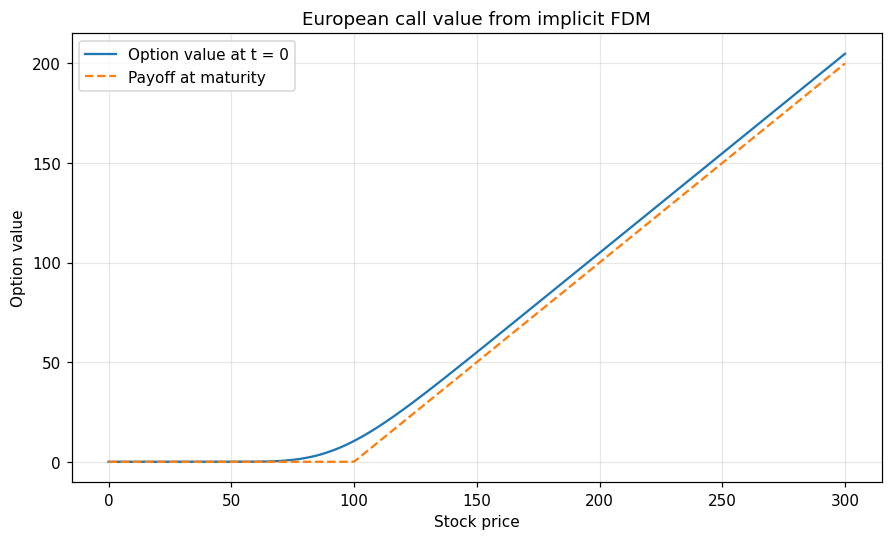

In [12]:
call_payoff = np.maximum(stock_grid - 100.0, 0.0)

fig, ax = plt.subplots(figsize=(8.0, 4.8), layout="constrained")
ax.plot(stock_grid, call_values, label="Option value at t = 0")
ax.plot(stock_grid, call_payoff, linestyle="--", label="Payoff at maturity")

ax.set_title("European call value from implicit FDM")
ax.set_xlabel("Stock price")
ax.set_ylabel("Option value")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

### FDM 결과의 put–call parity 확인

배당이 없으므로 $C-P=S_0-Ke^{-rT}$를 확인합니다. 수치해에는 이산화 오차가 있으므로 허용오차를 둡니다.

원문: `section08_pde_option_pricing.tex` · Listing 12 · 646행

In [13]:
left_side = call_price - put_price
right_side = 100.0 - 100.0 * np.exp(-0.05)

print(left_side)
print(right_side)
print(np.isclose(left_side, right_side, atol=2.0e-4))

4.876938650140834
4.877057549928594
True


**강의록 Listing 13**

강의록에 실린 비교용 출력입니다. 위 코드 셀의 출력은 이 노트북을 실제 실행해서 저장한 결과입니다.

```text
4.876938650140834
4.877057549928594
True
```

### 격자별 FDM 가격과 해석해 오차

공간격자와 시간격자를 함께 조정합니다. 보간오차 등 여러 오차가 결합되므로 절대오차가 모든 행에서 단조롭게 줄어들지는 않습니다.

원문: `section08_pde_option_pricing.tex` · Listing 14 · 690행

In [14]:
from scipy.stats import norm

d1 = (0.05 + 0.5 * 0.20**2) / 0.20
d2 = d1 - 0.20
exact_price = 100.0 * norm.cdf(d1) - 100.0 * np.exp(-0.05) * norm.cdf(d2)
grid_settings = [(100, 250), (200, 500), (400, 1000), (800, 2000)]
rows = []

for n_space, n_time in grid_settings:
    price, _, _ = black_scholes_pde_price(
        spot=100.0,
        strike=100.0,
        maturity=1.0,
        rate=0.05,
        volatility=0.20,
        s_max=300.0,
        n_space=n_space,
        n_time=n_time,
    )
    rows.append({
        "n_space": n_space,
        "n_time": n_time,
        "price": price,
        "absolute_error": abs(price - exact_price),
    })

print(pd.DataFrame(rows).to_string(index=False, float_format="%.8f"))

 n_space  n_time       price  absolute_error
     100     250 10.46154084      0.01095727
     200     500 10.45233714      0.00175357
     400    1000 10.45048787      0.00009570
     800    2000 10.45029838      0.00028520


**강의록 Listing 15**

강의록에 실린 비교용 출력입니다. 위 코드 셀의 출력은 이 노트북을 실제 실행해서 저장한 결과입니다.

```text
 n_space  n_time       price  absolute_error
     100     250 10.46154084      0.01095727
     200     500 10.45233714      0.00175357
     400    1000 10.45048787      0.00009570
     800    2000 10.45029838      0.00028520
```

**보충 그림: 격자오차**

가로축은 공간구간 수, 세로축은 해석해 대비 절대오차입니다. 표의 숫자를 그림으로도 확인합니다.

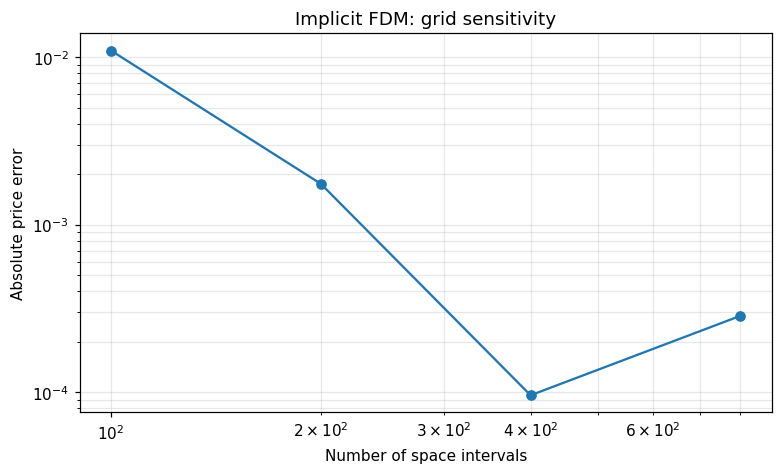

In [15]:
convergence = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.0, 4.2), layout="constrained")
ax.loglog(convergence["n_space"], convergence["absolute_error"], marker="o")
ax.set_xlabel("Number of space intervals")
ax.set_ylabel("Absolute price error")
ax.set_title("Implicit FDM: grid sensitivity")
ax.grid(True, which="both", alpha=0.3)
plt.show()

### 교육용 projected implicit American 가격함수

각 implicit 단계 뒤에 continuation value와 payoff 중 큰 값을 취하는 교육용 근사입니다. 일반적인 미국형 옵션의 선형상보성 문제를 정확히 푸는 전용 알고리즘과 구분해서 이해하세요.

원문: `section08_pde_option_pricing.tex` · Listing 16 · 783행

In [16]:
def projected_american_pde_price(
    spot,
    strike,
    maturity,
    rate,
    volatility,
    s_max,
    n_space,
    n_time,
    option_type="put",
    dividend_yield=0.0,
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    s_max = float(s_max)
    dividend_yield = float(dividend_yield)
    for name, value, minimum in (("n_space", n_space, 3), ("n_time", n_time, 1)):
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_space = int(n_space)
    n_time = int(n_time)
    option_type = str(option_type).lower()

    parameters = [spot, strike, maturity, rate, s_max, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("PDE parameters must be finite")
    if spot <= 0.0 or strike <= 0.0 or maturity <= 0.0:
        raise ValueError("spot, strike and maturity must be positive")
    if s_max <= max(spot, strike):
        raise ValueError("s_max must exceed both spot and strike")

    required_log_ratio = max((dividend_yield - rate) * maturity, 0.0)
    if np.log(s_max / strike) <= required_log_ratio:
        raise ValueError("s_max is too small for this boundary condition")

    if not np.isfinite(volatility) or volatility <= 0.0:
        raise ValueError("volatility must be finite and positive")

    stock_grid = np.linspace(0.0, s_max, num=n_space + 1)
    d_s = s_max / n_space
    d_tau = maturity / n_time
    payoff = option_payoff_grid(stock_grid, strike, option_type)
    values = payoff.copy()

    interior_stock = stock_grid[1:-1]
    diffusion = 0.5 * volatility**2 * interior_stock**2
    convection = (rate - dividend_yield) * interior_stock

    lower = diffusion / d_s**2 - convection / (2.0 * d_s)
    center = -2.0 * diffusion / d_s**2 - rate
    upper = diffusion / d_s**2 + convection / (2.0 * d_s)

    matrix = diags(
        diagonals=(
            -d_tau * lower[1:],
            1.0 - d_tau * center,
            -d_tau * upper[:-1],
        ),
        offsets=(-1, 0, 1),
        format="csc",
    )
    solver = splu(matrix)

    for step in range(n_time):
        tau = (step + 1) * d_tau

        if option_type == "put":
            left, right = strike, 0.0
        else:
            left = 0.0
            european_right = s_max * np.exp(-dividend_yield * tau)
            european_right -= strike * np.exp(-rate * tau)
            right = max(s_max - strike, european_right)

        right_hand_side = values[1:-1].copy()
        right_hand_side[0] += d_tau * lower[0] * left
        right_hand_side[-1] += d_tau * upper[-1] * right

        continuation = solver.solve(right_hand_side)
        values[1:-1] = np.maximum(continuation, payoff[1:-1])
        values[0] = left
        values[-1] = right

    return float(np.interp(spot, stock_grid, values))

### American put과 European put 비교

조기행사권을 가진 미국형 풋의 가격이 유럽형 풋보다 높은지 확인합니다.

원문: `section08_pde_option_pricing.tex` · Listing 17 · 877행

In [17]:
european_put, _, _ = black_scholes_pde_price(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
    s_max=300.0,
    n_space=400,
    n_time=1000,
    option_type="put",
)

american_put = projected_american_pde_price(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
    s_max=300.0,
    n_space=400,
    n_time=1000,
    option_type="put",
)

print(f"European put: {european_put:.6f}")
print(f"American put: {american_put:.6f}")

European put: 5.573549
American put: 6.088430


**강의록 Listing 18**

강의록에 실린 비교용 출력입니다. 위 코드 셀의 출력은 이 노트북을 실제 실행해서 저장한 결과입니다.

```text
European put: 5.573549
American put: 6.088430
```

### 일반적인 local volatility PDE 가격함수

local volatility가 시간과 주가에 따라 달라지므로 각 시간단계마다 행렬을 다시 구성합니다.

원문: `section08_pde_option_pricing.tex` · Listing 19 · 977행

In [18]:
def local_volatility_pde_price(
    spot,
    strike,
    maturity,
    rate,
    s_max,
    n_space,
    n_time,
    local_volatility,
    option_type="call",
    dividend_yield=0.0,
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    s_max = float(s_max)
    dividend_yield = float(dividend_yield)
    for name, value, minimum in (("n_space", n_space, 3), ("n_time", n_time, 1)):
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_space = int(n_space)
    n_time = int(n_time)
    option_type = str(option_type).lower()

    parameters = [spot, strike, maturity, rate, s_max, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("PDE parameters must be finite")
    if spot <= 0.0 or strike <= 0.0 or maturity <= 0.0:
        raise ValueError("spot, strike and maturity must be positive")
    if s_max <= max(spot, strike):
        raise ValueError("s_max must exceed both spot and strike")

    required_log_ratio = max((dividend_yield - rate) * maturity, 0.0)
    if np.log(s_max / strike) <= required_log_ratio:
        raise ValueError("s_max is too small for this boundary condition")

    stock_grid = np.linspace(0.0, s_max, num=n_space + 1)
    d_s = s_max / n_space
    d_tau = maturity / n_time
    values = option_payoff_grid(stock_grid, strike, option_type)
    interior_stock = stock_grid[1:-1]

    for step in range(n_time):
        tau = (step + 1) * d_tau
        calendar_time = maturity - tau

        sigma = np.asarray(local_volatility(calendar_time, interior_stock), dtype=float)
        sigma = np.broadcast_to(sigma, interior_stock.shape)

        if not np.isfinite(sigma).all() or np.any(sigma <= 0.0):
            raise ValueError("local volatility must be finite and positive")

        diffusion = 0.5 * sigma**2 * interior_stock**2
        convection = (rate - dividend_yield) * interior_stock

        lower = diffusion / d_s**2 - convection / (2.0 * d_s)
        center = -2.0 * diffusion / d_s**2 - rate
        upper = diffusion / d_s**2 + convection / (2.0 * d_s)

        matrix = diags(
            diagonals=(
                -d_tau * lower[1:],
                1.0 - d_tau * center,
                -d_tau * upper[:-1],
            ),
            offsets=(-1, 0, 1),
            format="csc",
        )

        left, right = european_boundary_values(
            tau,
            s_max,
            strike,
            rate,
            dividend_yield,
            option_type,
        )

        right_hand_side = values[1:-1].copy()
        right_hand_side[0] += d_tau * lower[0] * left
        right_hand_side[-1] += d_tau * upper[-1] * right

        values[1:-1] = splu(matrix).solve(right_hand_side)
        values[0] = left
        values[-1] = right

    price = np.interp(spot, stock_grid, values)
    return float(price), stock_grid, values

### CEV local volatility를 이용한 유럽형 콜옵션

기준주가에서의 변동성은 $\sigma_0=0.20$이고, $\beta=0.80$입니다. 행사가격은 이 예제에서 120입니다.

원문: `section08_pde_option_pricing.tex` · Listing 20 · 1077행

In [19]:
spot_reference = 100.0
sigma0 = 0.20
beta = 0.80


def cev_local_volatility(time, stock):
    del time
    safe_stock = np.maximum(stock, 1.0e-12)
    return sigma0 * (safe_stock / spot_reference) ** (beta - 1.0)


cev_price, cev_grid, cev_values = local_volatility_pde_price(
    spot=100.0,
    strike=120.0,
    maturity=1.0,
    rate=0.05,
    s_max=300.0,
    n_space=400,
    n_time=1000,
    local_volatility=cev_local_volatility,
)

print(f"CEV call price: {cev_price:.6f}")

CEV call price: 3.125753


**강의록 Listing 21**

강의록에 실린 비교용 출력입니다. 위 코드 셀의 출력은 이 노트북을 실제 실행해서 저장한 결과입니다.

```text
CEV call price: 3.125753
```

### Heston PDE의 9-point 공간연산자

2차원 배열의 행은 분산격자, 열은 주가격자입니다. 이 함수는 내부격자의 공간연산자만 반환하며 Heston 옵션가격 전체를 구하는 PDE solver는 아닙니다.

원문: `section08_pde_option_pricing.tex` · Listing 22 · 1170행

In [20]:
def heston_spatial_operator(
    values,
    stock_grid,
    variance_grid,
    rate,
    dividend_yield,
    kappa,
    theta,
    vol_of_variance,
    correlation,
):
    values = np.asarray(values, dtype=float)
    stock_grid = np.asarray(stock_grid, dtype=float)
    variance_grid = np.asarray(variance_grid, dtype=float)

    d_s = stock_grid[1] - stock_grid[0]
    d_v = variance_grid[1] - variance_grid[0]

    center_values = values[1:-1, 1:-1]

    value_s = (values[1:-1, 2:] - values[1:-1, :-2]) / (2.0 * d_s)
    value_ss = (values[1:-1, :-2] - 2.0 * center_values + values[1:-1, 2:]) / d_s**2

    value_v = (values[2:, 1:-1] - values[:-2, 1:-1]) / (2.0 * d_v)
    value_vv = (values[:-2, 1:-1] - 2.0 * center_values + values[2:, 1:-1]) / d_v**2

    value_sv = (
        values[2:, 2:] - values[2:, :-2] - values[:-2, 2:] + values[:-2, :-2]
    ) / (4.0 * d_s * d_v)

    stock, variance = np.meshgrid(stock_grid[1:-1], variance_grid[1:-1])

    operator = 0.5 * variance * stock**2 * value_ss
    operator += correlation * vol_of_variance * variance * stock * value_sv
    operator += 0.5 * vol_of_variance**2 * variance * value_vv
    operator += (rate - dividend_yield) * stock * value_s
    operator += kappa * (theta - variance) * value_v
    operator -= rate * center_values

    return operator

### 선택 연습 해설: Heston 격자와 공간연산자 확인

강의록의 $S\in[0,300]$, $v\in[0,0.50]$ 격자를 만듭니다. 만기 payoff는 분산 $v$에 의존하지 않습니다.
이어 매끄러운 함수 $f(S,v)=S^2+3Sv+2v^2$에 연산자를 적용하여 해석적 결과와 비교합니다.
이 검산은 미분 stencil을 확인하는 것으로, Heston 가격을 산출하는 실험은 아닙니다.

In [21]:
heston_stock_grid = np.linspace(0.0, 300.0, 121)
variance_grid = np.linspace(0.0, 0.50, 51)
stock_mesh, variance_mesh = np.meshgrid(heston_stock_grid, variance_grid)
payoff_2d = np.maximum(stock_mesh - 100.0, 0.0)
print("payoff shape:", payoff_2d.shape)

test_values = stock_mesh**2 + 3.0 * stock_mesh * variance_mesh + 2.0 * variance_mesh**2
numerical_operator = heston_spatial_operator(
    test_values, heston_stock_grid, variance_grid,
    rate=0.05, dividend_yield=0.0, kappa=2.0, theta=0.04,
    vol_of_variance=0.30, correlation=-0.70,
)
s = stock_mesh[1:-1, 1:-1]
v = variance_mesh[1:-1, 1:-1]
analytical_operator = v * s**2 + (-0.70) * 0.30 * v * s * 3.0
analytical_operator += 0.5 * 0.30**2 * v * 4.0
analytical_operator += 0.05 * s * (2.0 * s + 3.0 * v)
analytical_operator += 2.0 * (0.04 - v) * (3.0 * s + 4.0 * v)
analytical_operator -= 0.05 * (s**2 + 3.0 * s * v + 2.0 * v**2)
print("operator shape:", numerical_operator.shape)
print("maximum absolute stencil error:", np.max(np.abs(numerical_operator - analytical_operator)))

payoff shape: (51, 121)
operator shape: (49, 119)
maximum absolute stencil error: 7.410562830045819e-08


## 마무리 확인

- 공간구간 수와 격자점 수를 구분할 수 있나요?
- 경계값을 선형시스템의 우변에 넣는 이유를 설명할 수 있나요?
- put–call parity의 수치오차와 격자오차를 확인했나요?
- Heston 공간연산자와 완전한 Heston PDE 가격함수의 차이를 이해했나요?

**다음 실습:** Section 09에서 PDE 가격곡선의 1차·2차 차분으로 Delta와 Gamma를 계산합니다.